In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/orvile/carotid-ultrasound-images/dataset.csv
/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images/202202071355560051VAS_slice_351.png
/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images/202201121847410041VAS_slice_614.png
/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images/202202071308300020EM VASCULAR_slice_695.png
/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images/202202071314560026VAS_slice_65.png
/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images/202201

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings

from PIL import Image, ImageEnhance
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import joblib

# Căile datelor
IMAGES_PATH = "/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/US images"
MASKS_PATH  = "/kaggle/input/datasets/orvile/carotid-ultrasound-images/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images"
CARDIO_PATH = "/kaggle/input/datasets/sulianova/cardiovascular-disease-dataset/cardio_train.csv"
OUTPUT_DIR  = "/kaggle/working/"

IMG_SIZE = 256  # Dimensiunea la care redimensionăm toate imaginile

images_list = sorted(os.listdir(IMAGES_PATH))
masks_list  = sorted(os.listdir(MASKS_PATH))

print(f"Imagini: {len(images_list)} | Masti: {len(masks_list)}")
print(f"IMG_SIZE setat la: {IMG_SIZE}x{IMG_SIZE} px")

Imagini: 1100 | Masti: 1100
IMG_SIZE setat la: 256x256 px


In [3]:
def preprocess_image(img_path, size=IMG_SIZE):
    """
    Încarcă imaginea, o redimensionează și o normalizează.
    Returnează array numpy float32 în intervalul [0, 1].
    """
    img = Image.open(img_path).convert('L')      # Grayscale
    img = img.resize((size, size), Image.LANCZOS) # Resize
    arr = np.array(img, dtype=np.float32) / 255.0 # Normalizare [0,1]
    return arr

def preprocess_mask(mask_path, size=IMG_SIZE):
    """
    Încarcă masca, o redimensionează și o binarizează.
    Returnează array numpy float32: 0 = fundal, 1 = artera.
    """
    mask = Image.open(mask_path).convert('L')
    mask = mask.resize((size, size), Image.NEAREST)  # NEAREST păstrează binaritatea
    arr  = np.array(mask, dtype=np.float32) / 255.0
    arr  = (arr > 0.5).astype(np.float32)            # Binarizare strictă
    return arr

# Încarcă toate imaginile și măștile
print("Se încarcă imaginile... (poate dura 1-2 minute)")

all_images = []
all_masks  = []

for i, (img_name, mask_name) in enumerate(zip(images_list, masks_list)):
    img  = preprocess_image(os.path.join(IMAGES_PATH, img_name))
    mask = preprocess_mask(os.path.join(MASKS_PATH,  mask_name))
    all_images.append(img)
    all_masks.append(mask)

    if (i+1) % 100 == 0:
        print(f"  Procesate: {i+1}/{len(images_list)}")

all_images = np.array(all_images)  # Shape: (N, 256, 256)
all_masks  = np.array(all_masks)   # Shape: (N, 256, 256)

print(f"\n✅ Shape imagini: {all_images.shape}")
print(f"✅ Shape masti:   {all_masks.shape}")
print(f"✅ Valori imagini — min: {all_images.min():.2f}, max: {all_images.max():.2f}")
print(f"✅ Valori masti   — unice: {np.unique(all_masks)}")

Se încarcă imaginile... (poate dura 1-2 minute)
  Procesate: 100/1100
  Procesate: 200/1100
  Procesate: 300/1100
  Procesate: 400/1100
  Procesate: 500/1100
  Procesate: 600/1100
  Procesate: 700/1100
  Procesate: 800/1100
  Procesate: 900/1100
  Procesate: 1000/1100
  Procesate: 1100/1100

✅ Shape imagini: (1100, 256, 256)
✅ Shape masti:   (1100, 256, 256)
✅ Valori imagini — min: 0.00, max: 1.00
✅ Valori masti   — unice: [0. 1.]


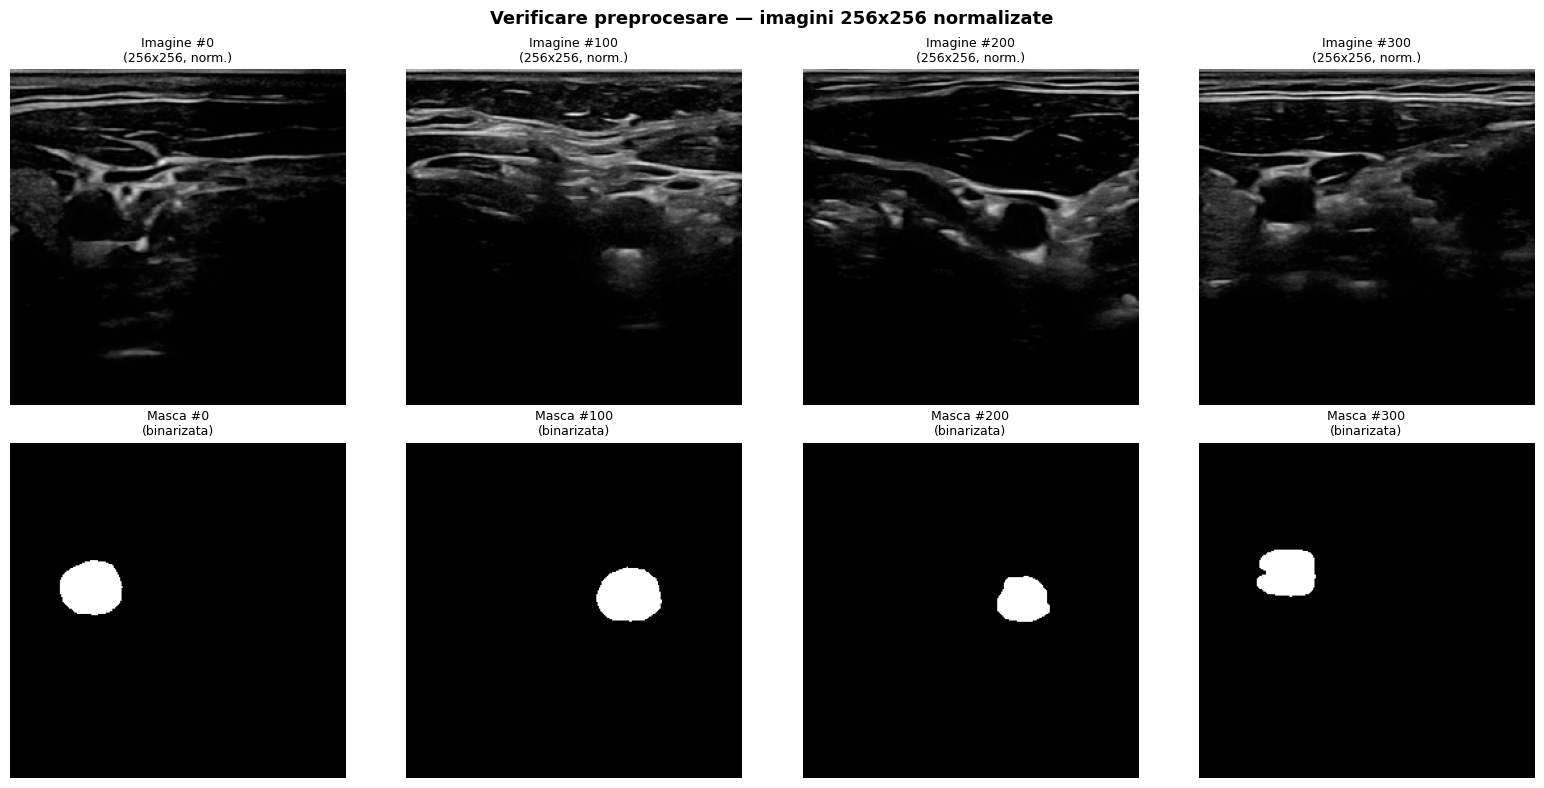

✅ Verificare vizuala OK!


In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Verificare preprocesare — imagini 256x256 normalizate', 
             fontsize=13, fontweight='bold')

for i in range(4):
    axes[0, i].imshow(all_images[i*100], cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(f'Imagine #{i*100}\n(256x256, norm.)', fontsize=9)
    axes[0, i].axis('off')

    axes[1, i].imshow(all_masks[i*100], cmap='gray', vmin=0, vmax=1)
    axes[1, i].set_title(f'Masca #{i*100}\n(binarizata)', fontsize=9)
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'verificare_preprocesare.png'), dpi=150)
plt.show()
print("✅ Verificare vizuala OK!")

In [5]:
def augment_image_mask(image, mask):
    """
    Aplică augmentări identice pe imagine și mască.
    Augmentările sunt IDENTICE pe ambele — masca trebuie să corespundă imaginii!
    """
    augmented_images = [image]
    augmented_masks  = [mask]

    # 1. Flip orizontal
    aug_img  = np.fliplr(image)
    aug_mask = np.fliplr(mask)
    augmented_images.append(aug_img)
    augmented_masks.append(aug_mask)

    # 2. Flip vertical
    aug_img  = np.flipud(image)
    aug_mask = np.flipud(mask)
    augmented_images.append(aug_img)
    augmented_masks.append(aug_mask)

    # 3. Variatie luminozitate (doar pe imagine, nu pe masca)
    pil_img = Image.fromarray((image * 255).astype(np.uint8))
    bright  = ImageEnhance.Brightness(pil_img).enhance(1.3)
    augmented_images.append(np.array(bright, dtype=np.float32) / 255.0)
    augmented_masks.append(mask)

    return augmented_images, augmented_masks

# Aplică augmentarea pe toate imaginile
print("Se aplica augmentarea datelor...")

aug_images, aug_masks = [], []
for i, (img, mask) in enumerate(zip(all_images, all_masks)):
    imgs, msks = augment_image_mask(img, mask)
    aug_images.extend(imgs)
    aug_masks.extend(msks)
    if (i+1) % 200 == 0:
        print(f"  Augmentate: {i+1}/{len(all_images)}")

aug_images = np.array(aug_images)
aug_masks  = np.array(aug_masks)

print(f"\n✅ Inainte de augmentare: {len(all_images)} imagini")
print(f"✅ Dupa augmentare:       {len(aug_images)} imagini (x4)")

Se aplica augmentarea datelor...
  Augmentate: 200/1100
  Augmentate: 400/1100
  Augmentate: 600/1100
  Augmentate: 800/1100
  Augmentate: 1000/1100

✅ Inainte de augmentare: 1100 imagini
✅ Dupa augmentare:       4400 imagini (x4)


✅ Split realizat:
   Train : 3080 imagini (70.0%)
   Val   : 660   imagini (15.0%)
   Test  : 660  imagini (15.0%)


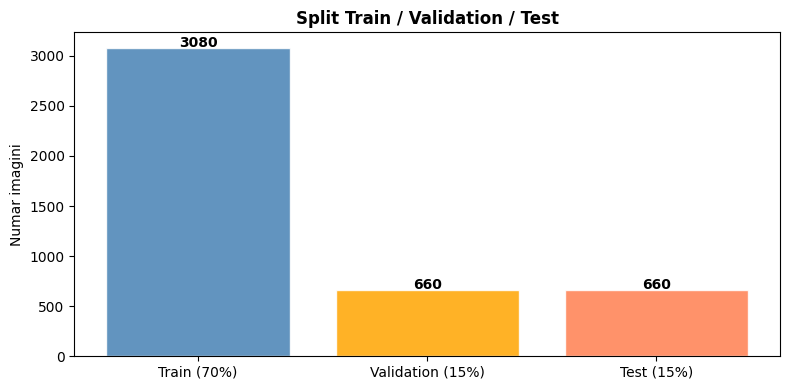

In [6]:
# Split stratificat 70 / 15 / 15
indices = np.arange(len(aug_images))

# Prima dată: 70% train, 30% temp
idx_train, idx_temp = train_test_split(
    indices, test_size=0.30, random_state=42
)

# Apoi: 30% temp → 15% val + 15% test
idx_val, idx_test = train_test_split(
    idx_temp, test_size=0.50, random_state=42
)

X_train = aug_images[idx_train]
X_val   = aug_images[idx_val]
X_test  = aug_images[idx_test]

y_train = aug_masks[idx_train]
y_val   = aug_masks[idx_val]
y_test  = aug_masks[idx_test]

print("✅ Split realizat:")
print(f"   Train : {len(X_train)} imagini ({len(X_train)/len(aug_images)*100:.1f}%)")
print(f"   Val   : {len(X_val)}   imagini ({len(X_val)/len(aug_images)*100:.1f}%)")
print(f"   Test  : {len(X_test)}  imagini ({len(X_test)/len(aug_images)*100:.1f}%)")

# Vizualizare split
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(['Train (70%)', 'Validation (15%)', 'Test (15%)'],
              [len(X_train), len(X_val), len(X_test)],
              color=['steelblue', 'orange', 'coral'], edgecolor='white', alpha=0.85)
for bar, val in zip(bars, [len(X_train), len(X_val), len(X_test)]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
            str(val), ha='center', fontweight='bold')
ax.set_title('Split Train / Validation / Test', fontweight='bold')
ax.set_ylabel('Numar imagini')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'grafic_split.png'), dpi=150)
plt.show()

In [9]:
df = pd.read_csv(CARDIO_PATH, sep=';')

# ── Curățare outlieri ──────────────────────────────────────────
df = df[(df['ap_hi'] >= 80)  & (df['ap_hi'] <= 240)]
df = df[(df['ap_lo'] >= 40)  & (df['ap_lo'] <= 150)]
df = df[(df['height'] >= 140) & (df['height'] <= 210)]
df = df[(df['weight'] >= 40)  & (df['weight'] <= 180)]
df = df[df['ap_hi'] > df['ap_lo']]  # Tensiunea sistolică > diastolică

print(f"✅ Dupa curatare: {len(df)} pacienti (din {len(pd.read_csv(CARDIO_PATH, sep=';'))})")

# ── Feature Engineering ───────────────────────────────────────
df['age_years']      = (df['age'] / 365).astype(int)
df['bmi']            = (df['weight'] / (df['height'] / 100) ** 2).round(1)
df['pulse_pressure'] = df['ap_hi'] - df['ap_lo']  # Presiunea pulsului

# Generare text clinic per pacient (pentru TF-IDF)
def generate_risk_text(row):
    """
    Transformă datele numerice ale unui pacient în text descriptiv.
    Acesta va fi vectorizat cu TF-IDF.
    """
    tokens = []

    # Vârstă
    if row['age_years'] > 65:   tokens.append('varstnic')
    elif row['age_years'] > 50: tokens.append('varsta_medie')
    else:                        tokens.append('tanar')

    # Tensiune
    if row['ap_hi'] > 160:      tokens.append('hipertensiv_grad2')
    elif row['ap_hi'] > 140:    tokens.append('hipertensiv_grad1')
    else:                        tokens.append('normotensiv')

    # IMC
    if row['bmi'] > 30:         tokens.append('obez')
    elif row['bmi'] > 25:       tokens.append('supraponderal')
    else:                        tokens.append('greutate_normala')

    # Colesterol
    if row['cholesterol'] == 3: tokens.append('colesterol_ridicat')
    elif row['cholesterol'] == 2: tokens.append('colesterol_mediu')
    else:                         tokens.append('colesterol_normal')

    # Glicemie
    if row['gluc'] == 3:        tokens.append('glicemie_ridicata')
    elif row['gluc'] == 2:      tokens.append('glicemie_medie')

    # Factori comportamentali
    if row['smoke']:             tokens.append('fumator')
    if row['alco']:              tokens.append('consum_alcool')
    if not row['active']:        tokens.append('sedentar')

    # Presiunea pulsului
    if row['pulse_pressure'] > 60: tokens.append('puls_diferential_mare')

    return ' '.join(tokens)

df['risk_text'] = df.apply(generate_risk_text, axis=1)

print("\n✅ Exemple de risk_text generat:")
print(df[['age_years', 'ap_hi', 'bmi', 'risk_text', 'cardio']].head(5).to_string())

✅ Dupa curatare: 68467 pacienti (din 70000)

✅ Exemple de risk_text generat:
   age_years  ap_hi   bmi                                                              risk_text  cardio
0         50    110  22.0                   tanar normotensiv greutate_normala colesterol_normal       0
1         55    140  34.9                       varsta_medie normotensiv obez colesterol_ridicat       1
2         51    130  23.5  varsta_medie normotensiv greutate_normala colesterol_ridicat sedentar       1
3         48    150  28.7                tanar hipertensiv_grad1 supraponderal colesterol_normal       1
4         47    100  23.0          tanar normotensiv greutate_normala colesterol_normal sedentar       0


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

# Features numerice, categorice și text
numeric_features  = ['age_years', 'ap_hi', 'ap_lo', 'bmi', 'pulse_pressure']
categoric_features = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']
text_feature      = 'risk_text'

# Split date clinice (stratificat pe target)
df_train, df_temp = train_test_split(df, test_size=0.30, random_state=42,
                                      stratify=df['cardio'])
df_val, df_test   = train_test_split(df_temp, test_size=0.50, random_state=42,
                                      stratify=df_temp['cardio'])

print(f"✅ Split date clinice:")
print(f"   Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

# Pipeline sklearn
preprocessor = ColumnTransformer(transformers=[
    ('num',  StandardScaler(),                     numeric_features),
    ('cat',  OneHotEncoder(handle_unknown='ignore'), categoric_features),
])

# Procesare separată pentru text (TF-IDF)
tfidf = TfidfVectorizer(max_features=100, ngram_range=(1,2))

# Fit pe train, transform pe val și test
X_train_tab = preprocessor.fit_transform(df_train[numeric_features + categoric_features])
X_val_tab   = preprocessor.transform(df_val[numeric_features + categoric_features])
X_test_tab  = preprocessor.transform(df_test[numeric_features + categoric_features])

X_train_tfidf = tfidf.fit_transform(df_train[text_feature])
X_val_tfidf   = tfidf.transform(df_val[text_feature])
X_test_tfidf  = tfidf.transform(df_test[text_feature])

# Concatenare features tabelare + TF-IDF
X_train_clinical = hstack([X_train_tab, X_train_tfidf])
X_val_clinical   = hstack([X_val_tab,   X_val_tfidf])
X_test_clinical  = hstack([X_test_tab,  X_test_tfidf])

y_train_clinical = df_train['cardio'].values
y_val_clinical   = df_val['cardio'].values
y_test_clinical  = df_test['cardio'].values

print(f"\n✅ Shape features clinice train: {X_train_clinical.shape}")
print(f"   (pacienti x features combinate tabelare+tfidf)")

✅ Split date clinice:
   Train: 47926 | Val: 10270 | Test: 10271

✅ Shape features clinice train: (47926, 92)
   (pacienti x features combinate tabelare+tfidf)


In [11]:
# Salvare imagini procesate
np.save(os.path.join(OUTPUT_DIR, 'X_train_img.npy'), X_train)
np.save(os.path.join(OUTPUT_DIR, 'X_val_img.npy'),   X_val)
np.save(os.path.join(OUTPUT_DIR, 'X_test_img.npy'),  X_test)
np.save(os.path.join(OUTPUT_DIR, 'y_train_img.npy'), y_train)
np.save(os.path.join(OUTPUT_DIR, 'y_val_img.npy'),   y_val)
np.save(os.path.join(OUTPUT_DIR, 'y_test_img.npy'),  y_test)

# Salvare date clinice procesate
df_train.to_csv(os.path.join(OUTPUT_DIR, 'clinical_train.csv'), index=False)
df_val.to_csv(os.path.join(OUTPUT_DIR,   'clinical_val.csv'),   index=False)
df_test.to_csv(os.path.join(OUTPUT_DIR,  'clinical_test.csv'),  index=False)

# Salvare preprocessor și tfidf (necesare pentru inferență și Streamlit)
joblib.dump(preprocessor, os.path.join(OUTPUT_DIR, 'preprocessor.pkl'))
joblib.dump(tfidf,        os.path.join(OUTPUT_DIR, 'tfidf_vectorizer.pkl'))

print("✅ Toate datele au fost salvate in Output!")
print("\n📁 Fisiere salvate:")
for f in sorted(os.listdir(OUTPUT_DIR)):
    size = os.path.getsize(os.path.join(OUTPUT_DIR, f)) / 1024
    print(f"   {f} — {size:.1f} KB")

✅ Toate datele au fost salvate in Output!

📁 Fisiere salvate:
   .virtual_documents — 4.0 KB
   X_test_img.npy — 168960.1 KB
   X_train_img.npy — 788480.1 KB
   X_val_img.npy — 168960.1 KB
   clinical_test.csv — 1147.5 KB
   clinical_train.csv — 5346.6 KB
   clinical_val.csv — 1144.1 KB
   grafic_split.png — 34.3 KB
   preprocessor.pkl — 3.0 KB
   tfidf_vectorizer.pkl — 4.8 KB
   verificare_preprocesare.png — 422.8 KB
   y_test_img.npy — 168960.1 KB
   y_train_img.npy — 788480.1 KB
   y_val_img.npy — 168960.1 KB
